In [ ]:
# --- INSTALAÇÃO DAS DEPENDÊNCIAS ---
try:
    import ultralytics
except ImportError:
    !pip install opencv-python ultralytics
!pip install pandas --no-cache-dir
import os
import glob
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import shutil
import random
import torch
import gc
import pandas as pd
from ultralytics import YOLO, settings
from IPython.display import display

In [ ]:
# Teste de Sanidade do Hardware Local
print(f"Executando em: {os.getcwd()}") # Deve mostrar E:\Projeto_Uva
print(f"Cores CUDA disponíveis: {torch.cuda.device_count()}")
print(f"Memória Total da GPU: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

Executando em: E:\Projeto_Uva
Cores CUDA disponíveis: 1
Memória Total da GPU: 19.99 GB


In [ ]:
import os
import gc
import torch
from ultralytics import settings

# ==============================================================================
# 1. SETUP & CONFIGURAÇÕES GERAIS
# ==============================================================================
gc.collect()
torch.cuda.empty_cache()

# --- CAMINHOS (Atualizados para o seu Disco E:) ---
# Como o servidor nasceu em E:\Projeto_Uva, usamos caminhos relativos ou absolutos
PROJETO_DIR = r'E:\Projeto_Uva\wgisd_projeto'

# Onde seu dataset WGISD já existe (ajuste o nome da pasta se for diferente)
PASTA_LOCAL = r'E:\Projeto_Uva\datasets\wgisd'
IMAGES_DIR = os.path.join(PASTA_LOCAL, 'images')
LABELS_DIR = os.path.join(PASTA_LOCAL, 'labels')

# --- CRIAÇÃO AUTOMÁTICA DA PASTA DE PROJETO ---
if not os.path.exists(PROJETO_DIR):
    os.makedirs(PROJETO_DIR, exist_ok=True)
    print(f"✅ Pasta criada com sucesso: {PROJETO_DIR}")

# Define onde o YOLO vai salvar as execuções (runs) no seu disco E:
settings.update({'runs_dir': os.path.join(PROJETO_DIR, 'runs')})

# --- VALIDAÇÃO DE SEGURANÇA ---
if os.path.exists(IMAGES_DIR) and os.path.exists(LABELS_DIR):
    num_imgs = len(os.listdir(IMAGES_DIR))
    print(f"🚀 Pronto para o treino! Detectadas {num_imgs} imagens em: {IMAGES_DIR}")
else:
    print(f"❌ Erro: Verifique se as pastas existem em: {PASTA_LOCAL}")
    print(f"Caminho Imagens: {IMAGES_DIR}")
    print(f"Caminho Labels: {LABELS_DIR}")

# --- FUNÇÃO GERADOR DE NOMES ÚNICOS ---
def obter_nome_unico(diretorio_pai, nome_base):
    contador = 0
    nome_candidato = nome_base
    while True:
        caminho_completo = os.path.join(diretorio_pai, nome_candidato)
        if not os.path.exists(caminho_completo):
            return nome_candidato
        contador += 1
        nome_candidato = f"{nome_base}_{contador}"

🚀 Pronto para o treino! Detectadas 300 imagens em: E:\Projeto_Uva\datasets\wgisd\images


In [ ]:
# ==============================================================================
# 2. PREPARAÇÃO INTELIGENTE DO DATASET L)
# ==============================================================================

# Onde ficam os arquivos train.txt e test.txt originais
BASE_DATASETS = r'E:\Projeto_Uva\datasets'

def preparar_dataset_inteligente(nome_arquivo_original, output_name):
    caminhos_finais = []

    # Caminho completo do arquivo de entrada (ex: /home/.../train.txt)
    caminho_lista = os.path.join(BASE_DATASETS, nome_arquivo_original)

    # Caminho onde salvaremos a lista formatada para o YOLO dentro do projeto
    caminho_output_yolo = os.path.join(PROJETO_DIR, output_name)

    if os.path.exists(caminho_lista):
        with open(caminho_lista, 'r') as f:
            linhas = f.readlines()

        for line in linhas:
            line = line.strip()
            if not line: continue

            # Pega apenas o nome do arquivo (ex: 'uva1.jpg')
            nome_base = os.path.basename(line)
            # Garante que a extensão seja .jpg (caso no txt esteja diferente)
            nome_correto = f"{os.path.splitext(nome_base)[0]}.jpg"

            # Como as imagens já estão em IMAGES_DIR, apenas montamos o caminho final
            caminho_imagem_vm = os.path.join(IMAGES_DIR, nome_correto)

            if os.path.exists(caminho_imagem_vm):
                caminhos_finais.append(caminho_imagem_vm)

    # Gera o arquivo txt final que o YOLO vai ler
    if caminhos_finais:
        with open(caminho_output_yolo, 'w') as f:
            for p in caminhos_finais:
                f.write(f'{p}\n')

    return caminhos_finais

print("\n--- ⚙️ Verificando Dataset na VM ---")

# Lendo os arquivos originais que estão na pasta principal de datasets
imgs_treino = preparar_dataset_inteligente('train.txt', 'yolo_train.txt')
imgs_teste  = preparar_dataset_inteligente('test.txt', 'yolo_test.txt')

# Se as listas estiverem vazias (ex: os txt não foram encontrados), faz o split automático
if len(imgs_treino) == 0:
    print("⚠️ Listas .txt não encontradas ou vazias. Fazendo split automático 80/20...")
    todas = glob.glob(os.path.join(IMAGES_DIR, '*.jpg'))
    if todas:
        random.shuffle(todas)
        split = int(len(todas)*0.8)
        imgs_treino = todas[:split]
        imgs_teste = todas[split:]

        # Salva as novas listas na pasta do projeto
        with open(os.path.join(PROJETO_DIR, 'yolo_train.txt'), 'w') as f:
            f.writelines([x+'\n' for x in imgs_treino])
        with open(os.path.join(PROJETO_DIR, 'yolo_test.txt'), 'w') as f:
            f.writelines([x+'\n' for x in imgs_teste])

# --- GERAÇÃO DO ARQUIVO YAML (MAPA DO YOLO) ---
yaml_path = os.path.join(PROJETO_DIR, 'wgisd.yaml')
with open(yaml_path, 'w') as f:
    # No YAML, apontamos para os arquivos que acabamos de criar na pasta do projeto
    f.write(f"train: {os.path.join(PROJETO_DIR, 'yolo_train.txt')}\n")
    f.write(f"val: {os.path.join(PROJETO_DIR, 'yolo_test.txt')}\n")
    f.write(f"names:\n  0: uva\n")

print(f"✅ DATASET PRONTO: {len(imgs_treino)} treino, {len(imgs_teste)} teste.")
print(f"📍 Arquivo YAML configurado em: {yaml_path}")


--- ⚙️ Verificando Dataset na VM ---
✅ DATASET PRONTO: 242 treino, 58 teste.
📍 Arquivo YAML configurado em: E:\Projeto_Uva\wgisd_projeto\wgisd.yaml


In [ ]:
# ==============================================================================
# 3. TREINAMENTO (YOLO) - OTIMIZADO PARA RTX 4000
# ==============================================================================
# Define o nome base
BASE_NOME_TREINO = 'wgisd_treino_baga'

# Gera o nome único na pasta do Disco E:
NOME_TREINO_ATUAL = obter_nome_unico(os.path.join(PROJETO_DIR, 'runs'), BASE_NOME_TREINO)

print(f"\n--- 🚀 INICIANDO TREINAMENTO NA RTX 4000 ADA (20GB) ---")
print(f"📁 Pasta do Treino: {NOME_TREINO_ATUAL}")

# Carrega o modelo (Segmentação para bagas de uva)
model = YOLO('yolov8n-seg.pt')

# O arquivo YAML deve estar em E:\Projeto_Uva\wgisd.yaml
caminho_yaml = os.path.join(PROJETO_DIR, 'wgisd.yaml')

model.train(
    data=caminho_yaml,
    epochs=50,
    patience=20,
    batch=32,          # Aumentado para aproveitar os 20GB de VRAM
    imgsz=640,
    project=PROJETO_DIR,
    name=NOME_TREINO_ATUAL,
    exist_ok=True,
    device=0,
    workers=8,         # Usa os cores do seu Xeon para o dataloader
    amp=True           # Ativa precisão mista para treinar ainda mais rápido
)


--- 🚀 INICIANDO TREINAMENTO NA RTX 4000 ADA (20GB) ---
📁 Pasta do Treino: wgisd_treino_baga
Ultralytics 8.4.14  Python-3.10.19 torch-2.5.1 CUDA:0 (NVIDIA RTX 4000 Ada Generation, 20474MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\Projeto_Uva\wgisd_projeto\wgisd.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, na

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001101CC71090>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.0410

In [ ]:
# ==============================================================================
# 4. ALGORITMO DE VISÃO: BAGAS DE ELITE
# ==============================================================================
def encontrar_bagas_elite(img_rgb, mascara_cacho, max_bagas_por_cacho=5):
    """
    Combina Hough Transform + Distance Transform + Non-Maximum Suppression
    para encontrar apenas as bagas mais confiáveis dentro de um cacho.
    """
    mascara_cacho = mascara_cacho.astype(np.uint8)
    img_isolada = cv2.bitwise_and(img_rgb, img_rgb, mask=mascara_cacho)
    gray = cv2.cvtColor(img_isolada, cv2.COLOR_RGB2GRAY)

    # Pré-processamento (Contraste alto + Blur leve)

    clahe = cv2.createCLAHE(clipLimit=4.0, tileGridSize=(8,8))
    enhanced = clahe.apply(gray)
    enhanced = cv2.GaussianBlur(enhanced, (3, 3), 0)

    # Detecção de Círculos

    circles = cv2.HoughCircles(enhanced, cv2.HOUGH_GRADIENT, dp=1.0, minDist=15,
                               param1=50, param2=25, minRadius=6, maxRadius=32)

    candidatos = []
    # Mapa de distância: pixels claros = centro do cacho

    dist_transform = cv2.distanceTransform(mascara_cacho, cv2.DIST_L2, 5)

    if circles is not None:
        circles = np.round(circles[0, :]).astype("int")
        for (x, y, r) in circles:
            if y >= mascara_cacho.shape[0] or x >= mascara_cacho.shape[1]: continue
            if mascara_cacho[y, x] == 0: continue

            # Filtro: Prioriza uvas centrais (longe da borda)
            dist_borda = dist_transform[y, x]
            if dist_borda > r * 0.5:
                candidatos.append((x, y, r, dist_borda))

    candidatos.sort(key=lambda x: x[3], reverse=True)
    bagas_finais = []

    # Supressão de Sobreposição (NMS)
    for c_atual in candidatos:
        x1, y1, r1, score1 = c_atual
        sobrepoe = False

        for c_ok in bagas_finais:
            x2, y2, r2 = c_ok
            dist = np.sqrt((x1-x2)**2 + (y1-y2)**2)
            if dist < (r1 + r2) * 0.8:
                sobrepoe = True
                break

        if not sobrepoe:
            bagas_finais.append((x1, y1, r1))
            if len(bagas_finais) >= max_bagas_por_cacho:
                break

    return bagas_finais

In [ ]:
# ==============================================================================
# 5. ANÁLISE COMPLETA
# ==============================================================================
PIXELS_POR_CM = 42.0
def iniciar_analise_completa(n_ciclos=3):
    print("\n" + "="*60)
    print("🍇 ANÁLISE COMPLETA: GERAÇÃO DE TABELA DETALHADA")
    print("="*60 + "\n")

    # 1. Cria pasta de resultados única (INCREMENTAL)
    BASE_NOME_RESULTADOS = 'resultados_analise_uva'
    nome_pasta_resultados = obter_nome_unico(PROJETO_DIR, BASE_NOME_RESULTADOS)

    pasta_salvamento = os.path.join(PROJETO_DIR, nome_pasta_resultados)
    os.makedirs(pasta_salvamento)

    print(f"📂 Resultados serão salvos em: {pasta_salvamento}")

    # 2. Carrega o modelo
    path_best = os.path.join(PROJETO_DIR, NOME_TREINO_ATUAL, 'weights/best.pt')

    if os.path.exists(path_best):
        print(f"✅ Usando pesos do treino atual: {NOME_TREINO_ATUAL}")
        model_final = YOLO(path_best)
    else:
        print("⚠️ Pesos não encontrados. Usando modelo base.")
        model_final = YOLO('yolov8n-seg.pt')

    # 3. Seleciona Amostra
    lista_imgs = glob.glob(os.path.join(IMAGES_DIR, '*.jpg'))
    if not lista_imgs: return
    amostra = random.sample(lista_imgs, min(n_ciclos, len(lista_imgs)))

    # 4. Loop de Processamento
    for img_path in amostra:
        nome_arq = os.path.basename(img_path)
        nome_sem_ext = os.path.splitext(nome_arq)[0]
        print(f"\nProcessando: {nome_arq}...")

        res = model_final.predict(img_path, conf=0.2, imgsz=640, retina_masks=True, verbose=False)[0]
        img_rgb = cv2.cvtColor(res.orig_img, cv2.COLOR_BGR2RGB)

        fig, ax = plt.subplots(1, 1, figsize=(16, 12))
        ax.imshow(img_rgb)
        ax.axis('off')

        dados_da_imagem = []

        if res.masks:
            for i, mask_data in enumerate(res.masks.data):
                coords = res.masks.xy[i]

                mask_arr = mask_data.cpu().numpy().squeeze()
                mask_arr = cv2.resize(mask_arr, (img_rgb.shape[1], img_rgb.shape[0]))

                # Tenta medir bagas
                bagas = encontrar_bagas_elite(img_rgb, mask_arr, max_bagas_por_cacho=5)

                medidas_cacho = []
                for (bx, by, br) in bagas:
                    d_mm = (br * 2 / PIXELS_POR_CM) * 10
                    medidas_cacho.append(d_mm)

                    # Desenho visual das bagas
                    circ = patches.Circle((bx, by), br, ec='red', fc='none', lw=2)
                    ax.add_patch(circ)
                    ax.scatter(bx, by, c='yellow', s=10, marker='.')

                # --- LÓGICA DE DADOS E VISUALIZAÇÃO ---
                x_min = min(c[0] for c in coords)
                y_min = min(c[1] for c in coords)

                if medidas_cacho:
                    # SUCESSO: Tem medidas
                    media_cacho = sum(medidas_cacho) / len(medidas_cacho)
                    min_cacho = min(medidas_cacho)
                    max_cacho = max(medidas_cacho)

                    poly = patches.Polygon(coords, closed=True, fc='none', ec='#00FF00', lw=2, ls='-')
                    texto_label = f"#{i+1}: {media_cacho:.1f}mm"
                    cor_fundo = '#00FF00'


                    dados_da_imagem.append({
                        'Arquivo': nome_arq,
                        'Cacho_ID': i+1,
                        'Qtd_Bagas': len(medidas_cacho),
                        'Diametro_Medio_mm': round(media_cacho, 2),
                        'Diametro_Min_mm': round(min_cacho, 2),
                        'Diametro_Max_mm': round(max_cacho, 2)
                    })
                else:
                    # FALHA: Não conseguiu medir bagas (mas o cacho existe)
                    poly = patches.Polygon(coords, closed=True, fc='none', ec='orange', lw=1, ls='--')
                    texto_label = f"#{i+1}: S/ Dados"
                    cor_fundo = 'orange'

                    # Salva zeros para manter a tabela consistente
                    dados_da_imagem.append({
                        'Arquivo': nome_arq,
                        'Cacho_ID': i+1,
                        'Qtd_Bagas': 0,
                        'Diametro_Medio_mm': 0.0,
                        'Diametro_Min_mm': 0.0,
                        'Diametro_Max_mm': 0.0
                    })

                ax.add_patch(poly)
                ax.text(x_min, y_min - 10, texto_label, color='black', fontsize=9, fontweight='bold',
                        bbox=dict(facecolor=cor_fundo, alpha=0.7, edgecolor='black', boxstyle='round,pad=0.2'))

        # Título
        qtd_total = len(dados_da_imagem)
        # Conta quantos tiveram sucesso (qtd > 0)
        qtd_medidos = len([d for d in dados_da_imagem if d['Qtd_Bagas'] > 0])

        ax.set_title(f"Img: {nome_arq} | Detectados: {qtd_total} | Medidos: {qtd_medidos}",
                     fontweight='bold', fontsize=14)

        plt.tight_layout()

        # Salva Imagem
        caminho_img = os.path.join(pasta_salvamento, f"visual_{nome_arq}")
        plt.savefig(caminho_img)

        # Salva Tabela CSV
        if dados_da_imagem:
            df = pd.DataFrame(dados_da_imagem)
            # Ordena as colunas
            colunas_ordem = ['Arquivo', 'Cacho_ID', 'Qtd_Bagas', 'Diametro_Medio_mm', 'Diametro_Min_mm', 'Diametro_Max_mm']
            df = df[colunas_ordem]

            caminho_csv = os.path.join(pasta_salvamento, f"dados_{nome_sem_ext}.csv")
            df.to_csv(caminho_csv, index=False)
            display(df)

        plt.show()
        print(f"✅ Salvo em: {caminho_img}")
        time.sleep(1)

# --- EXECUÇÃO ---
iniciar_analise_completa(58)


🍇 ANÁLISE COMPLETA: GERAÇÃO DE TABELA DETALHADA

📂 Resultados serão salvos em: E:\Projeto_Uva\wgisd_projeto\resultados_analise_uva_2
✅ Usando pesos do treino atual: wgisd_treino_baga

Processando: CSV_1894.jpg...


,Arquivo,Cacho_ID,Qtd_Bagas,Diametro_Medio_mm,Diametro_Min_mm,Diametro_Max_mm
0,CSV_1894.jpg,1,5,6.38,4.76,8.10
1,CSV_1894.jpg,2,5,6.19,5.71,7.62
2,CSV_1894.jpg,3,5,7.81,5.24,14.76
3,CSV_1894.jpg,4,5,7.90,5.71,12.38
4,CSV_1894.jpg,5,5,8.19,4.76,14.76
5,CSV_1894.jpg,6,5,7.24,5.71,10.48
6,CSV_1894.jpg,7,5,6.67,5.71,8.57
7,CSV_1894.jpg,8,5,6.86,5.24,8.57
8,CSV_1894.jpg,9,5,7.33,5.71,9.52
9,CSV_1894.jpg,10,5,7.81,3.33,13.81


<Figure size 1600x1200 with 1 Axes>

✅ Salvo em: E:\Projeto_Uva\wgisd_projeto\resultados_analise_uva_2\visual_CSV_1894.jpg

Processando: SVB_20180427_152106643_HDR.jpg...


,Arquivo,Cacho_ID,Qtd_Bagas,Diametro_Medio_mm,Diametro_Min_mm,Diametro_Max_mm
0,SVB_20180427_152106643_HDR.jpg,1,5,6.48,3.33,13.81
1,SVB_20180427_152106643_HDR.jpg,2,3,9.21,6.67,14.29
2,SVB_20180427_152106643_HDR.jpg,3,5,6.00,3.33,8.57
3,SVB_20180427_152106643_HDR.jpg,4,5,7.05,4.76,8.10
4,SVB_20180427_152106643_HDR.jpg,5,5,8.48,3.33,13.81
5,SVB_20180427_152106643_HDR.jpg,6,5,5.90,4.29,9.05
6,SVB_20180427_152106643_HDR.jpg,7,5,7.14,4.76,8.57
7,SVB_20180427_152106643_HDR.jpg,8,5,6.00,5.24,6.67
8,SVB_20180427_152106643_HDR.jpg,9,5,8.76,4.29,14.76
9,SVB_20180427_152106643_HDR.jpg,10,5,5.81,4.76,7.14


<Figure size 1600x1200 with 1 Axes>

... (165 outputs left out)

✅ Salvo em: E:\Projeto_Uva\wgisd_projeto\resultados_analise_uva_2\visual_SVB_1969.jpg

Processando: SVB_1939.jpg...


,Arquivo,Cacho_ID,Qtd_Bagas,Diametro_Medio_mm,Diametro_Min_mm,Diametro_Max_mm
0,SVB_1939.jpg,1,5,9.52,5.24,14.76
1,SVB_1939.jpg,2,5,9.05,7.62,10.00
2,SVB_1939.jpg,3,5,9.14,6.67,14.29
3,SVB_1939.jpg,4,4,11.43,4.76,14.76
4,SVB_1939.jpg,5,5,9.33,4.76,12.38
5,SVB_1939.jpg,6,5,7.33,5.71,8.57
6,SVB_1939.jpg,7,4,8.33,6.67,10.48
7,SVB_1939.jpg,8,5,8.57,6.67,10.48
8,SVB_1939.jpg,9,5,8.57,7.14,10.00
9,SVB_1939.jpg,10,5,8.95,8.10,10.48


<Figure size 1600x1200 with 1 Axes>

✅ Salvo em: E:\Projeto_Uva\wgisd_projeto\resultados_analise_uva_2\visual_SVB_1939.jpg


In [ ]:
import os
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

# --- 1. CONFIGURAÇÃO DOS CAMINHOS ---
# Altere para o caminho onde está o seu modelo salvo
PATH_MODELO = r'E:\Projeto_Uva\wgisd_projeto\wgisd_treino_baga\weights\best.pt'
# Pasta com as fotos novas que você quer testar
PASTA_TESTE = r'E:\Projeto_Uva\video_demo_frames'
# Onde salvar as predições visuais
SAIDA_TESTE = r'E:\Projeto_Uva\testes_resultados'

os.makedirs(SAIDA_TESTE, exist_ok=True)

# --- 2. CARREGAR O MODELO NA GPU ---
model = YOLO(PATH_MODELO)

# --- 3. EXECUTAR PREDIÇÃO ---
# O parâmetro 'save=True' já cria uma pasta com as imagens desenhadas
results = model.predict(
    source=PASTA_TESTE,
    conf=0.50,      # Confiança mínima (ajuste conforme necessário)
    device=0,       # Usa sua RTX 4000
    save=True,      # Salva as fotos com os boxes/máscaras
    project=SAIDA_TESTE,
    name='experimento_1'
)

print(f"✅ Teste concluído! Fotos salvas em: {SAIDA_TESTE}")


image 1/500 E:\Projeto_Uva\video_demo_frames\frame-00001.jpg: 384x640 13 uvas, 60.2ms
image 2/500 E:\Projeto_Uva\video_demo_frames\frame-00003.jpg: 384x640 11 uvas, 11.6ms
image 3/500 E:\Projeto_Uva\video_demo_frames\frame-00005.jpg: 384x640 12 uvas, 10.6ms
image 4/500 E:\Projeto_Uva\video_demo_frames\frame-00007.jpg: 384x640 10 uvas, 8.0ms
image 5/500 E:\Projeto_Uva\video_demo_frames\frame-00009.jpg: 384x640 8 uvas, 6.3ms
image 6/500 E:\Projeto_Uva\video_demo_frames\frame-00011.jpg: 384x640 9 uvas, 7.7ms
image 7/500 E:\Projeto_Uva\video_demo_frames\frame-00013.jpg: 384x640 11 uvas, 6.1ms
image 8/500 E:\Projeto_Uva\video_demo_frames\frame-00015.jpg: 384x640 11 uvas, 6.9ms
image 9/500 E:\Projeto_Uva\video_demo_frames\frame-00017.jpg: 384x640 10 uvas, 10.4ms
image 10/500 E:\Projeto_Uva\video_demo_frames\frame-00019.jpg: 384x640 9 uvas, 8.8ms
image 11/500 E:\Projeto_Uva\video_demo_frames\frame-00021.jpg: 384x640 9 uvas, 9.7ms
image 12/500 E:\Projeto_Uva\video_demo_frames\frame-00023.jpg:

In [ ]:
# import os
# import shutil
# from ultralytics import YOLO

# # --- 1. CONFIGURAÇÃO DE CAMINHOS ---
# # Caminho do modelo que você acabou de treinar
# PATH_ORIGINAL = r'E:\Projeto_Uva\wgisd_projeto\wgisd_treino_baga\weights\best.pt'

# # Nova pasta onde você quer centralizar os modelos para o Hardware/IoT
# PASTA_EXPORT = r'E:\Projeto_Uva\modelos_finalizados'

# # --- 2. CRIAÇÃO DA PASTA ---
# if not os.path.exists(PASTA_EXPORT):
#     os.makedirs(PASTA_EXPORT)
#     print(f"✅ Pasta criada com sucesso: {PASTA_EXPORT}")

# # --- 3. CARREGAR E EXPORTAR PARA ONNX ---
# try:
#     print("--- 📦 Iniciando conversão para ONNX (Aguarde...) ---")
#     model = YOLO(PATH_ORIGINAL)

#     # O comando export salva o arquivo .onnx na mesma pasta do .pt original
#     path_onnx_gerado = model.export(format='onnx', dynamic=True)

#     # --- 4. MOVER PARA A PASTA DE DESTINO ---
#     nome_arquivo = os.path.basename(path_onnx_gerado)
#     caminho_final = os.path.join(PASTA_EXPORT, nome_arquivo)

#     # Move o arquivo para a pasta organizada
#     shutil.move(path_onnx_gerado, caminho_final)

#     print("\n" + "="*50)
#     print(f"🚀 SUCESSO! Modelo ONNX pronto para o Hardware.")
#     print(f"📍 Localização: {caminho_final}")
#     print("="*50)

# except Exception as e:
#     print(f"❌ Erro na exportação: {e}")
#     print("Verifique se o caminho do 'best.pt' está correto no seu disco E.")

--- 📦 Iniciando conversão para ONNX (Aguarde...) ---
Ultralytics 8.4.14  Python-3.10.19 torch-2.5.1 CPU (Intel Xeon w7-2475X)
 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
YOLOv8n-seg summary (fused): 86 layers, 3,258,259 parameters, 0 gradients, 11.3 GFLOPs

PyTorch: starting from 'E:\Projeto_Uva\wgisd_projeto\wgisd_treino_baga\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 37, 8400), (1, 32, 160, 160)) (6.5 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxslim>=0.1.71', 'onnxruntime-gpu'] not found, attempting AutoUpdate...
   ---------------------------------------- 0.0/16.4 MB ? eta -:--:--
   ---- ----------------------------------- 1.8/16.4 MB 20.2 MB/s eta 0:00:01
   ------------ --------------------------- 5.0/16.4 MB 23.2 MB/s eta 0:00:01
   ------------ --------------------------- 5.2/16.4 MB 10.6 MB/s eta 0:00:02
   ---------

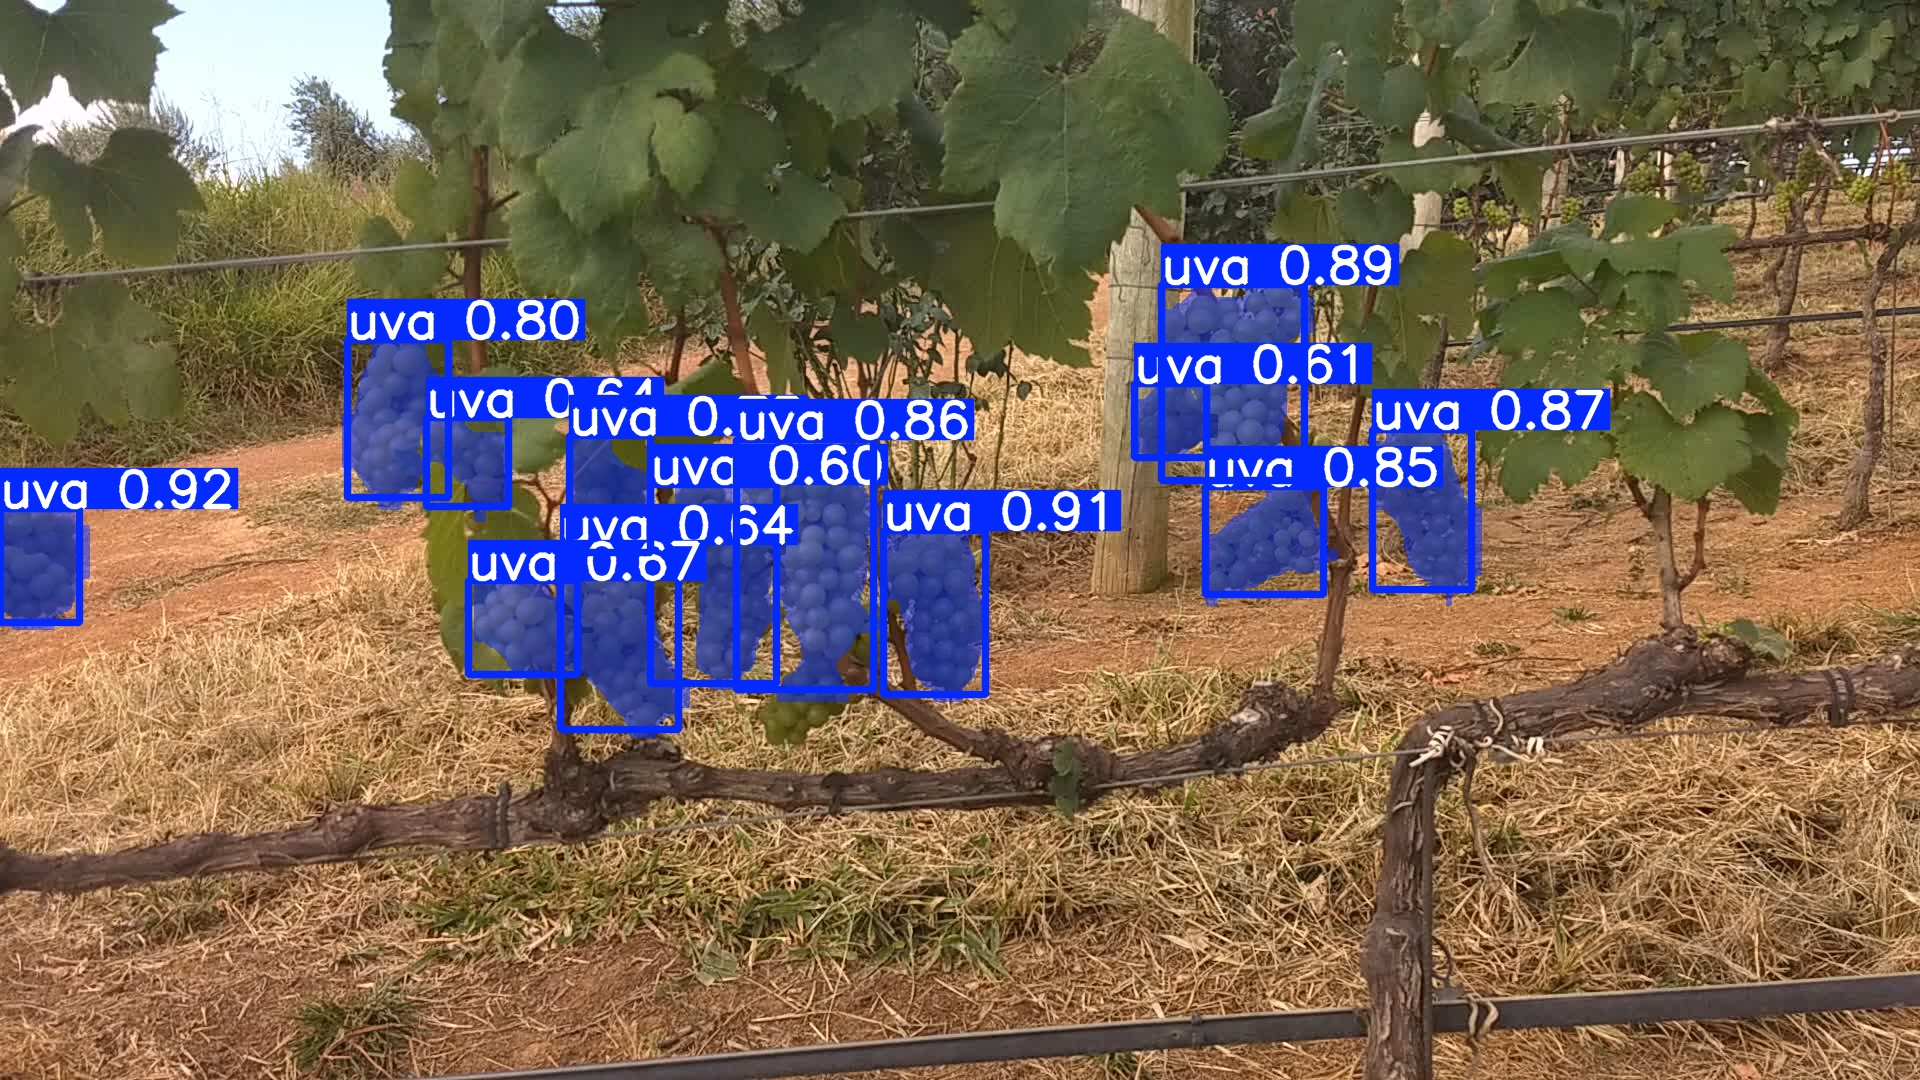

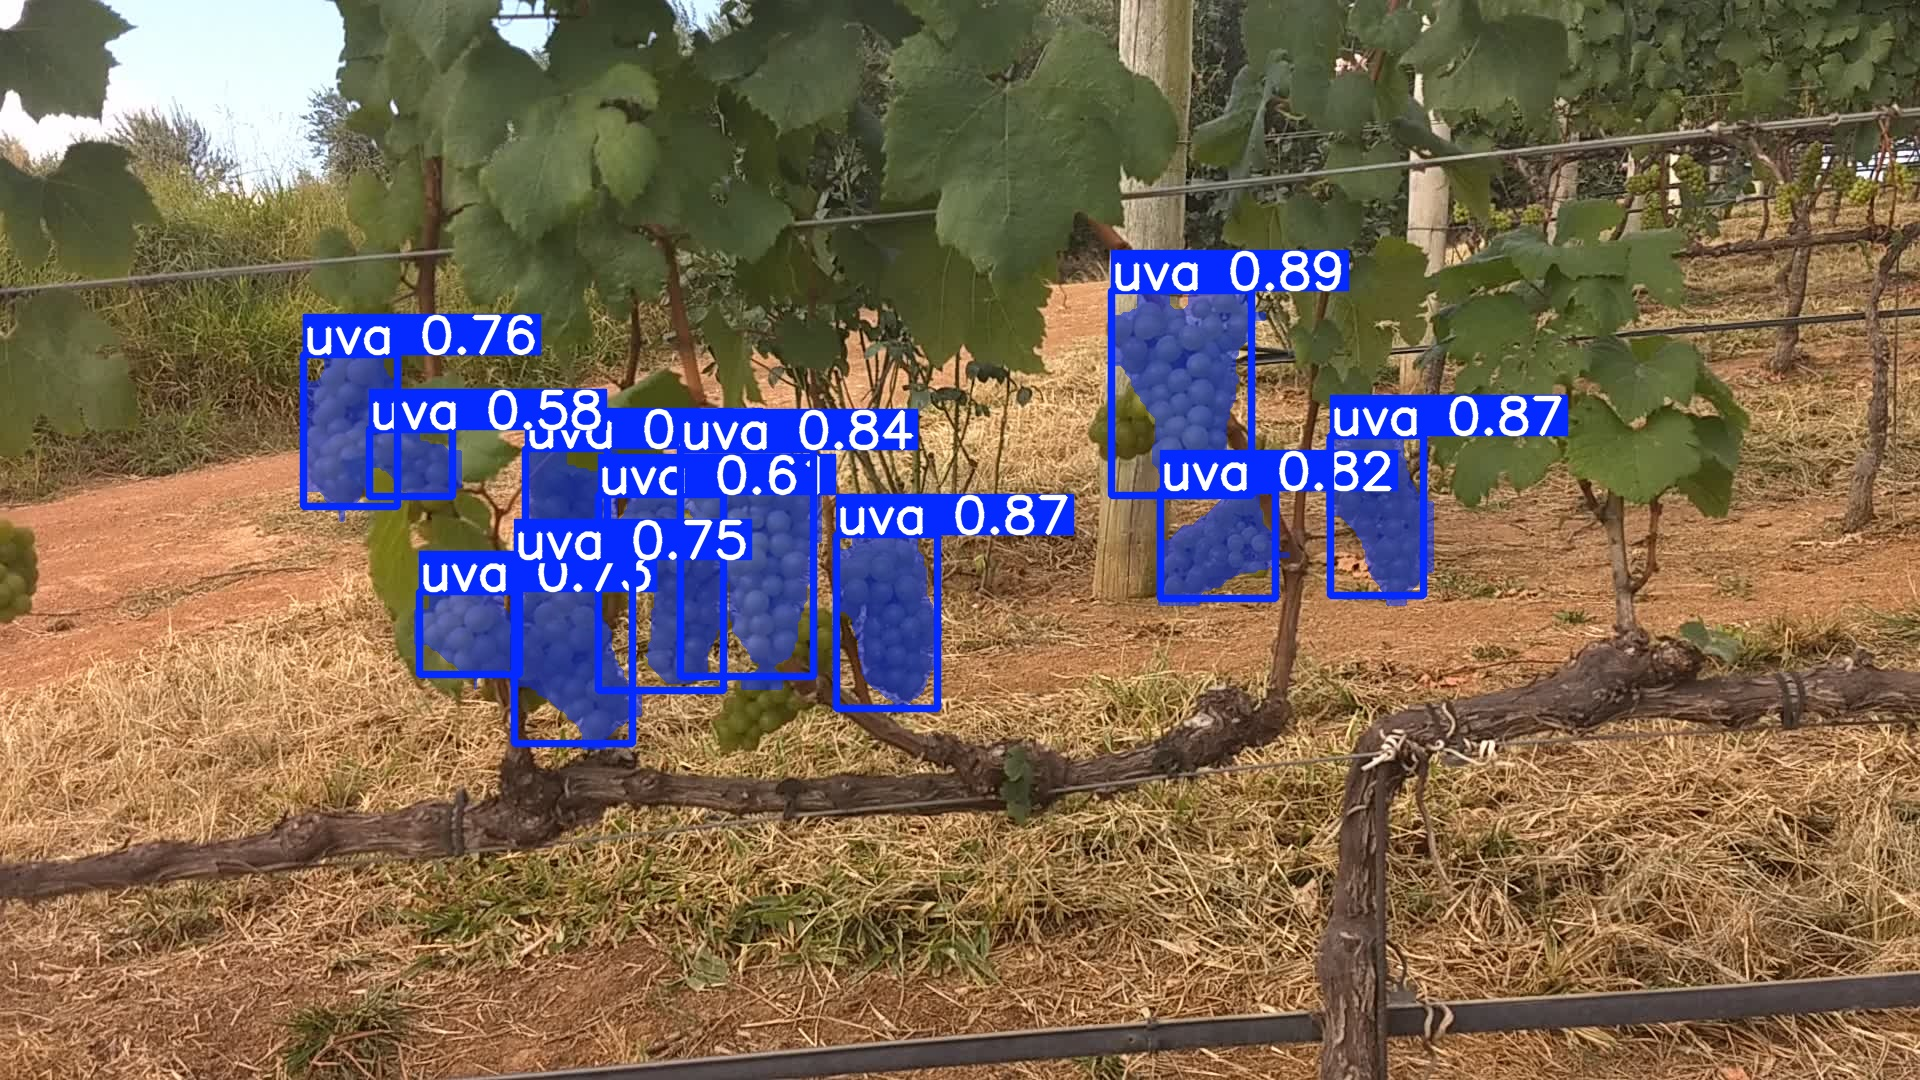

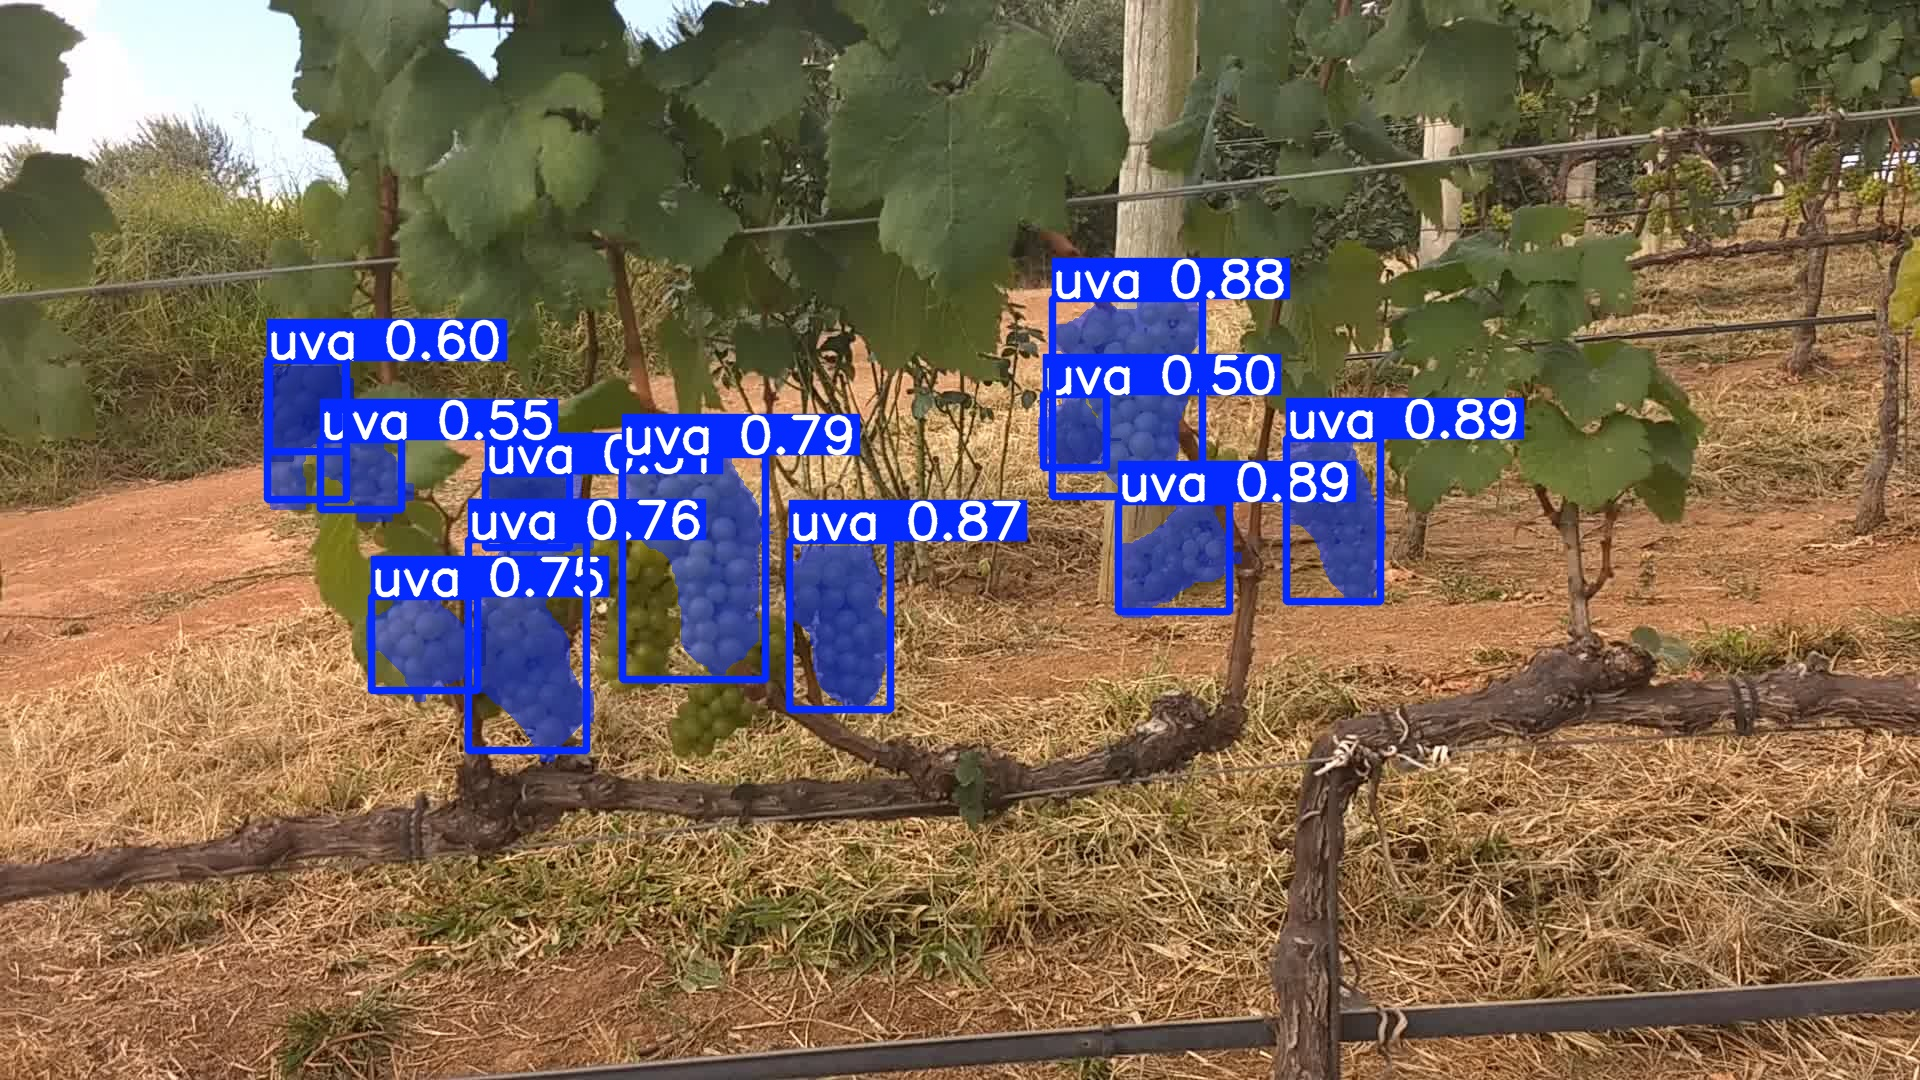

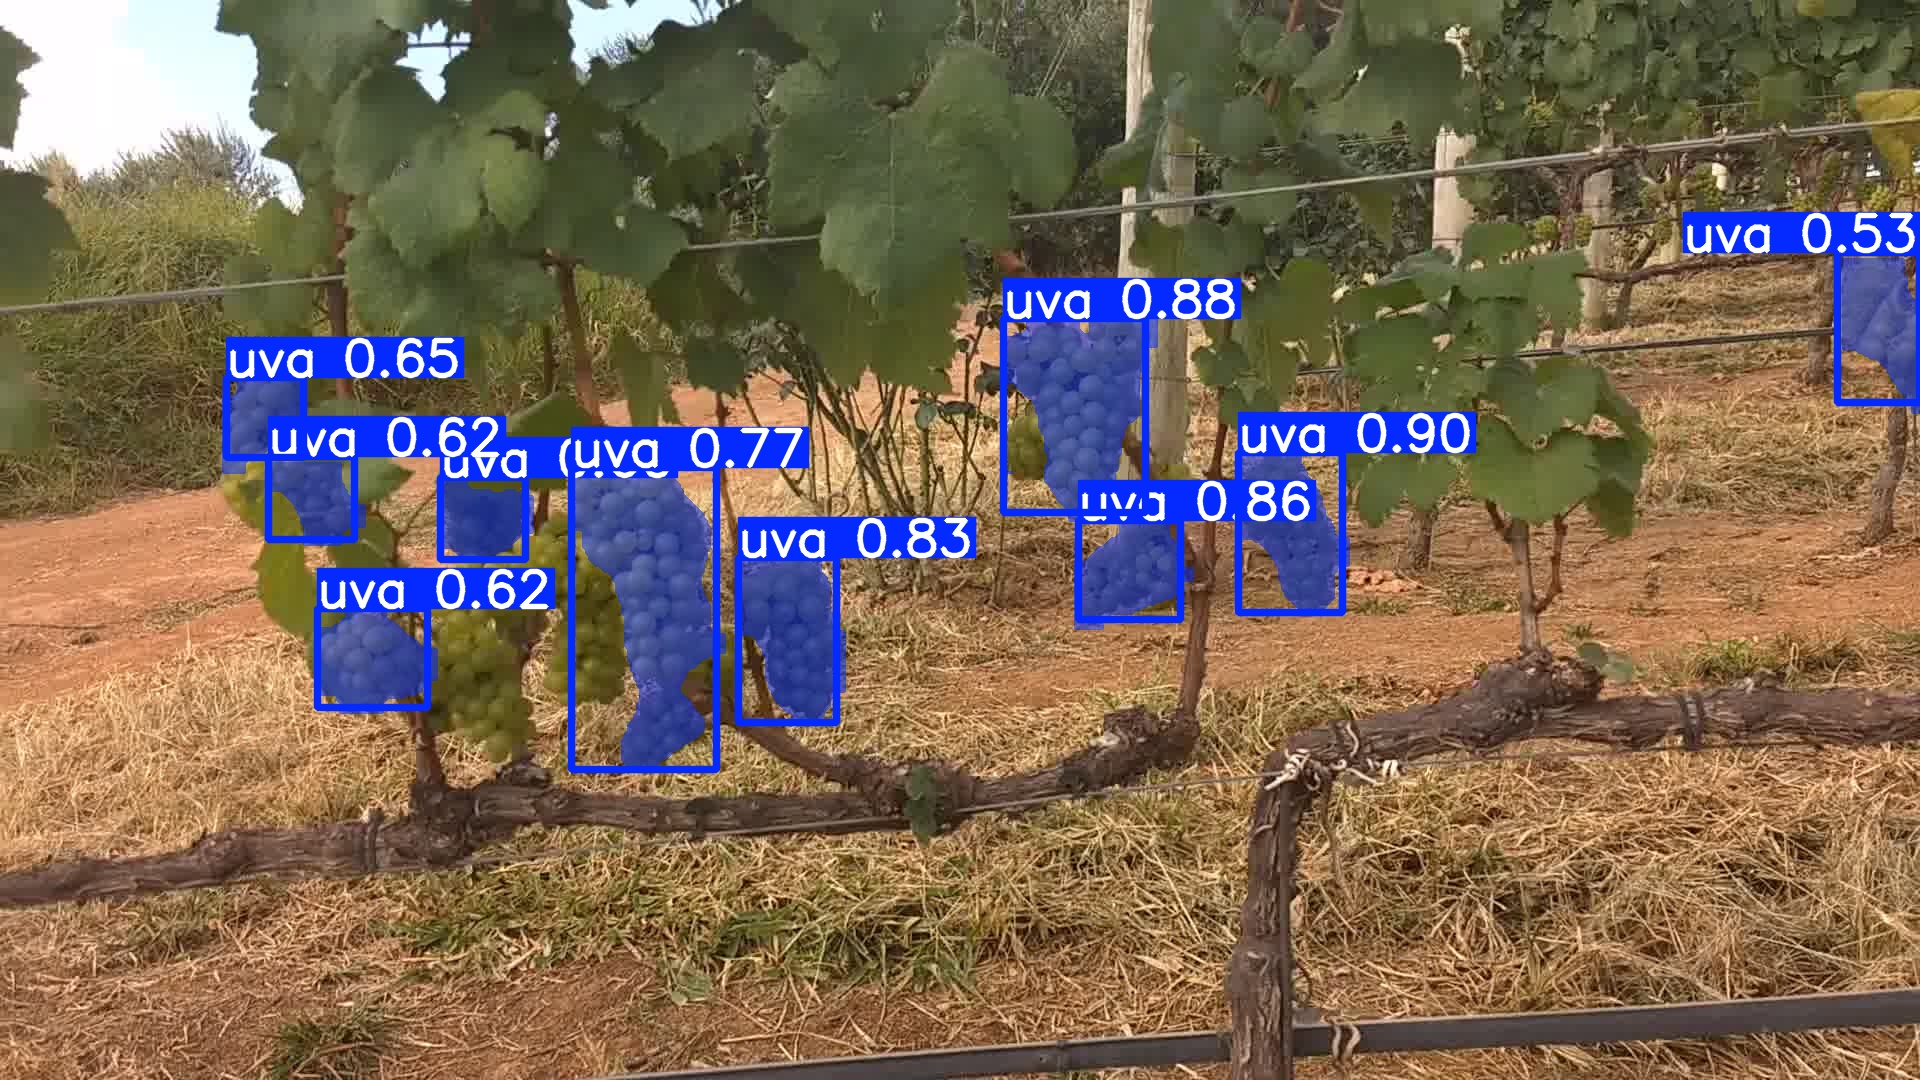

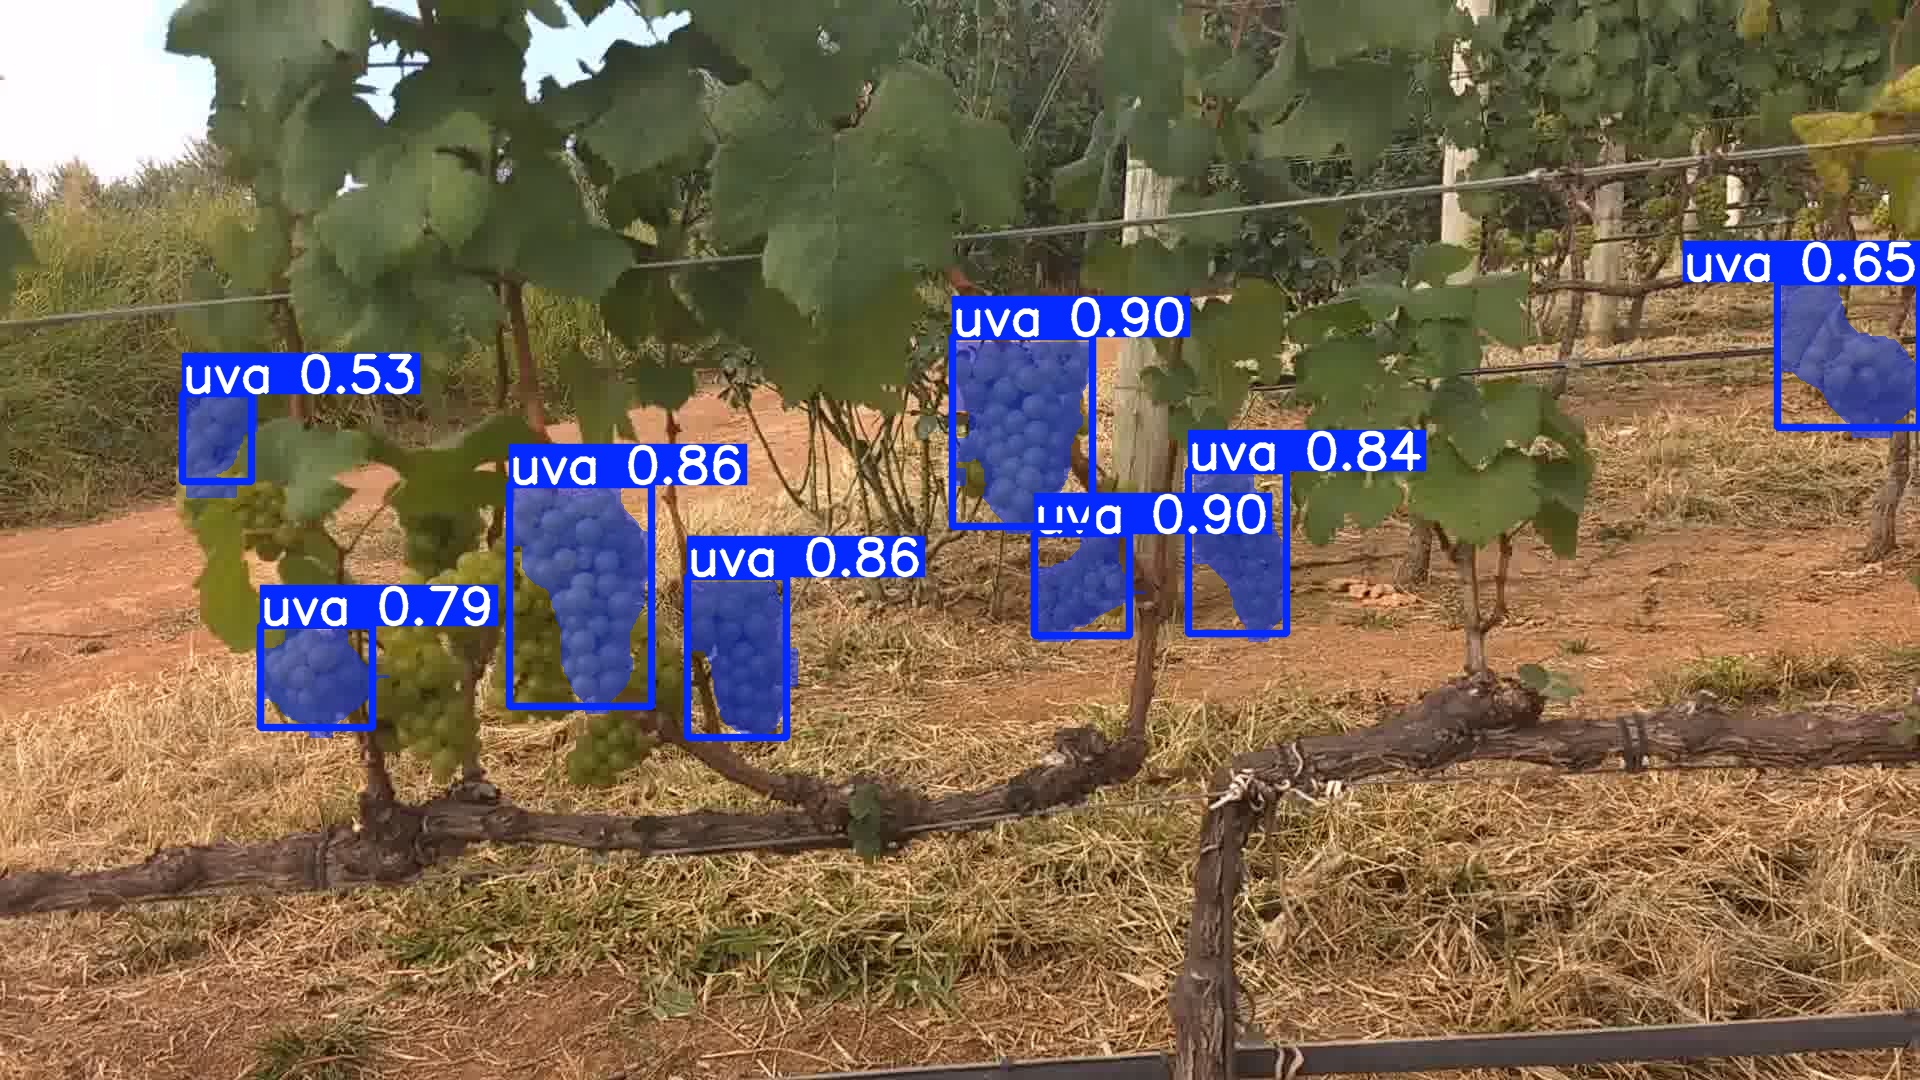

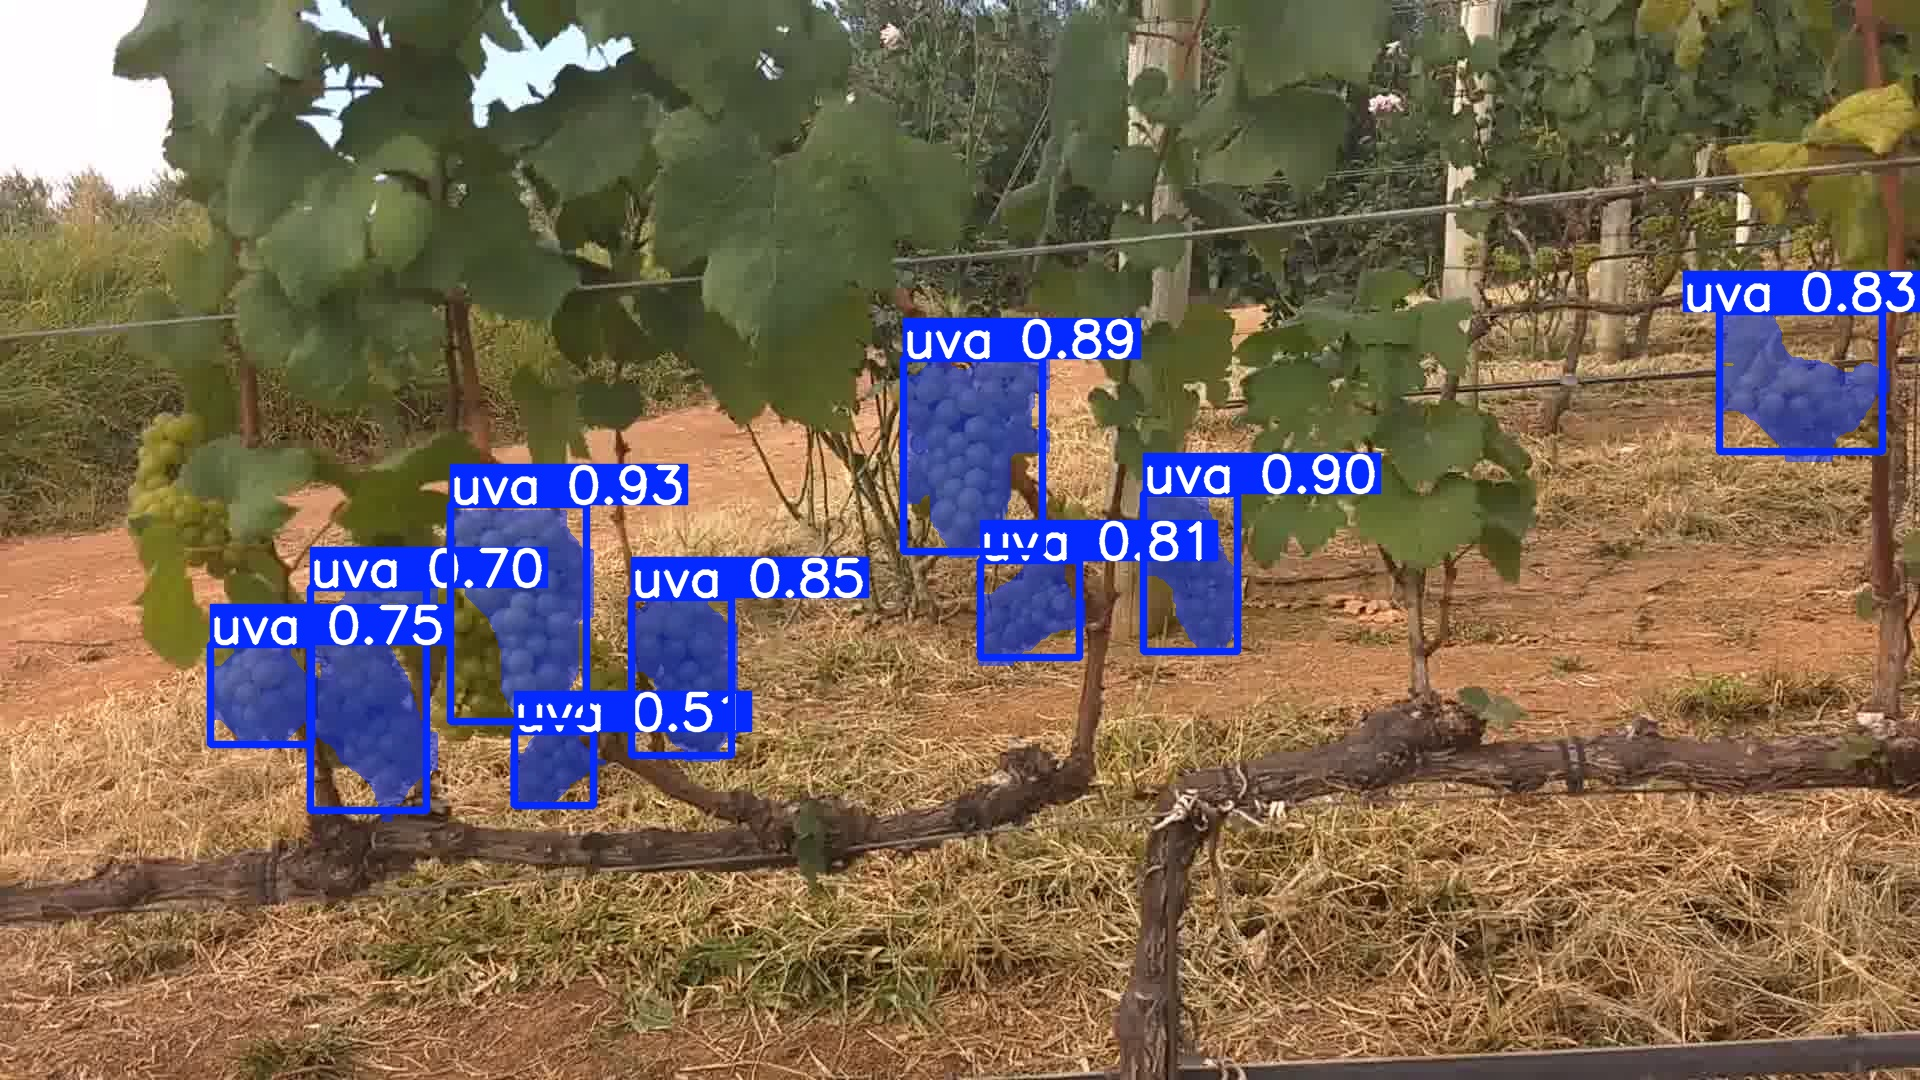

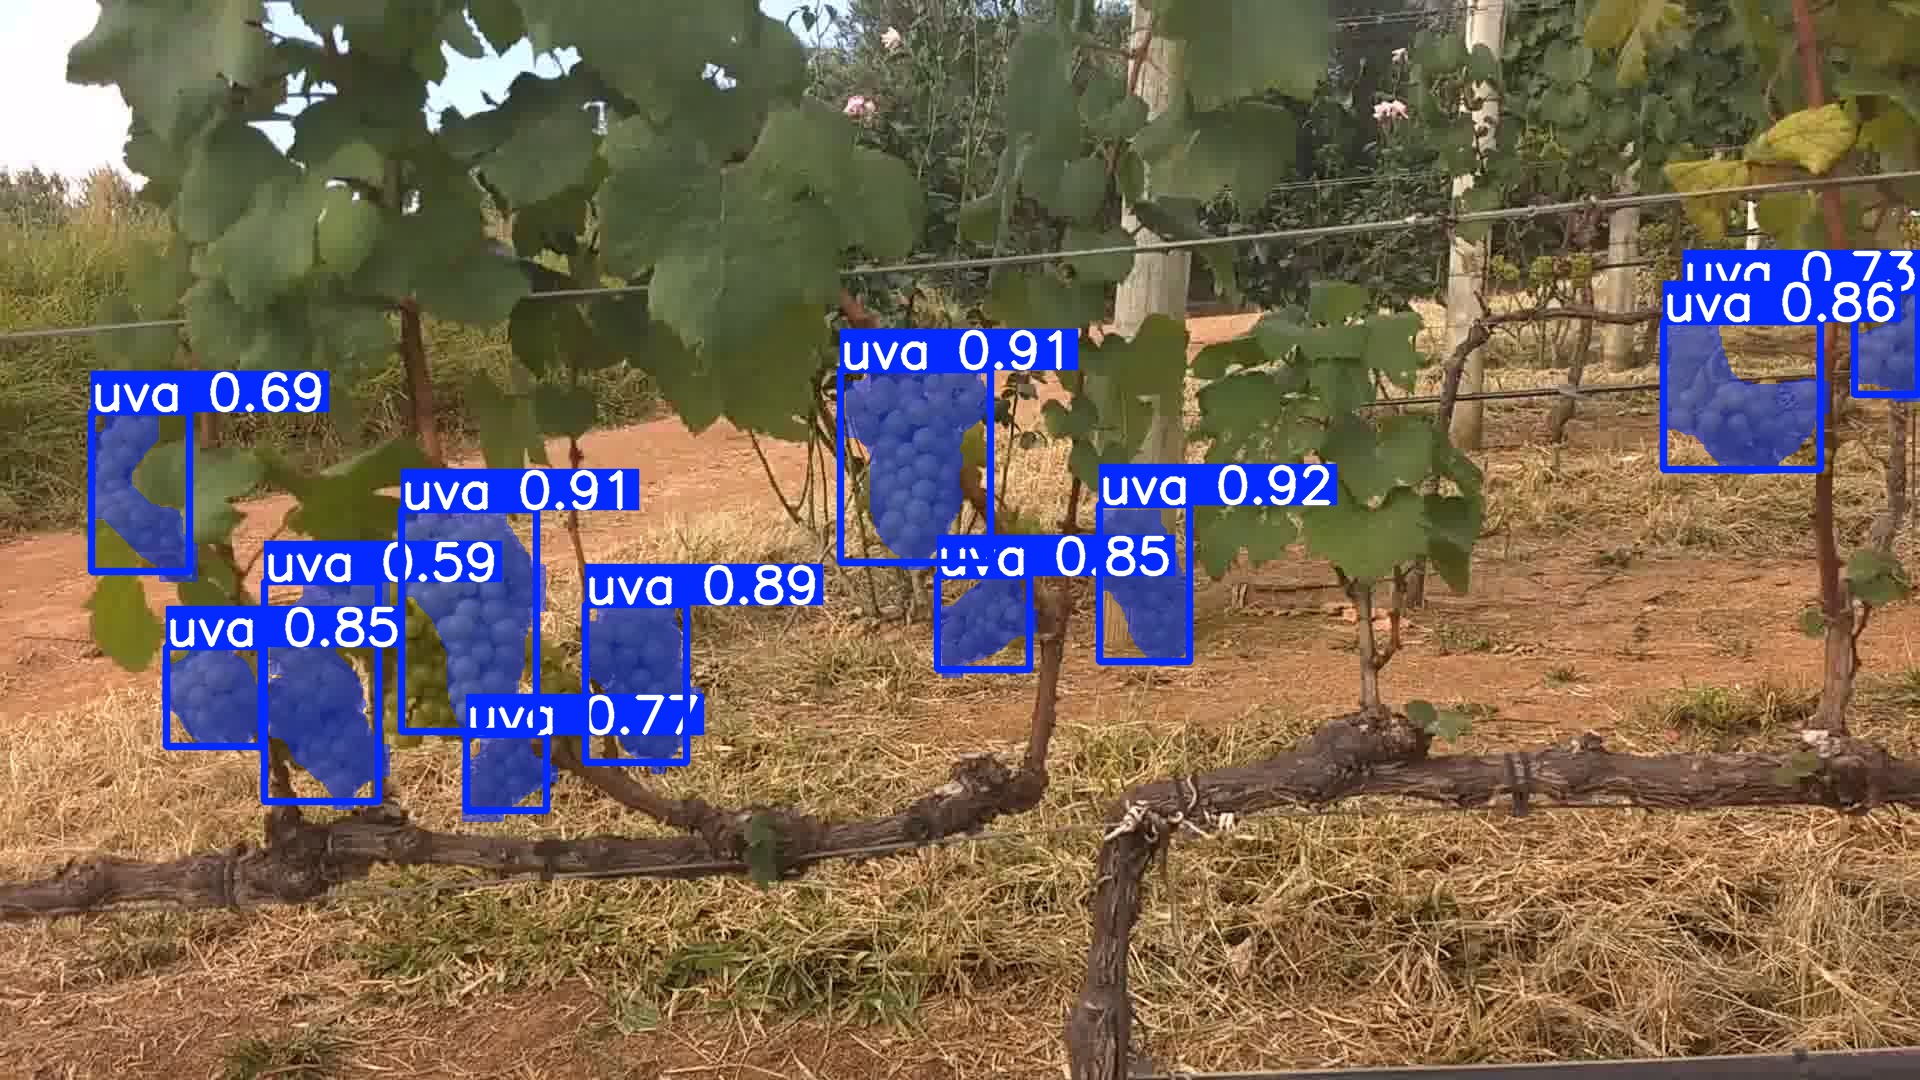

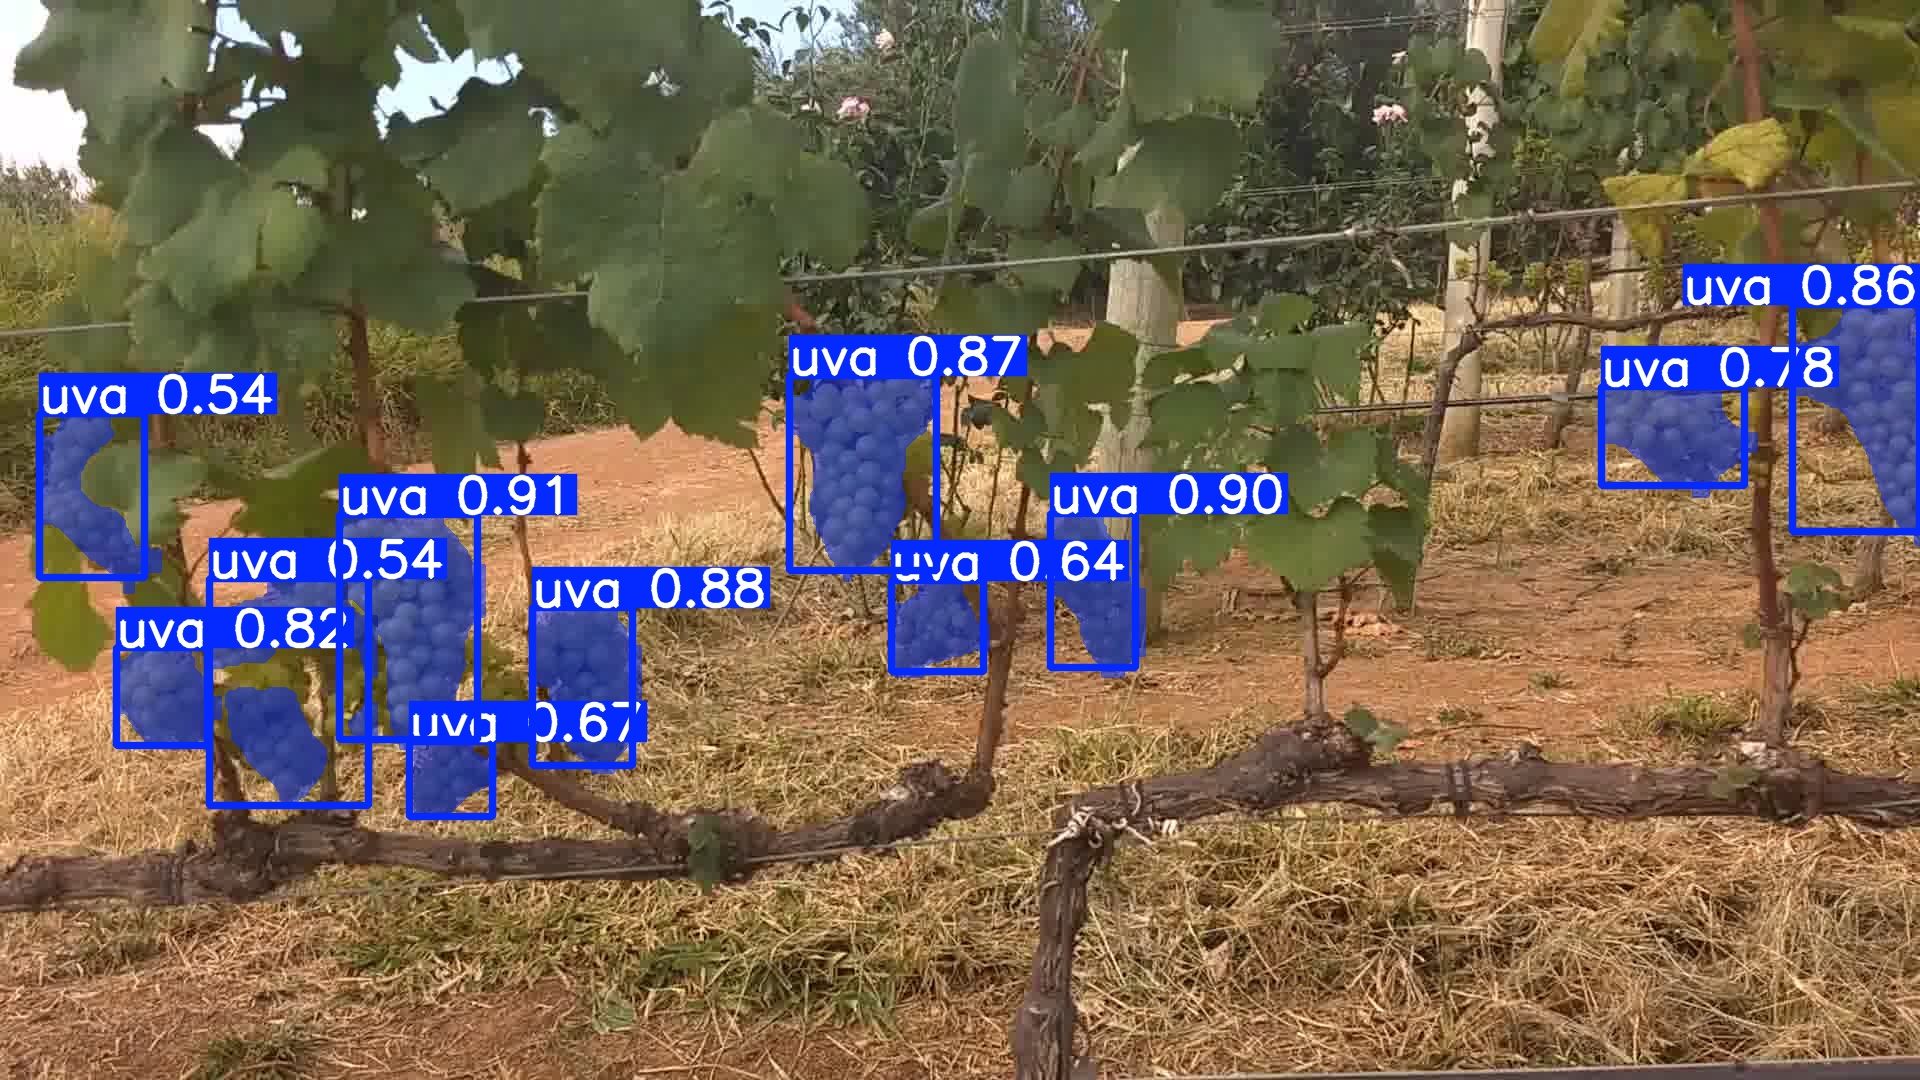

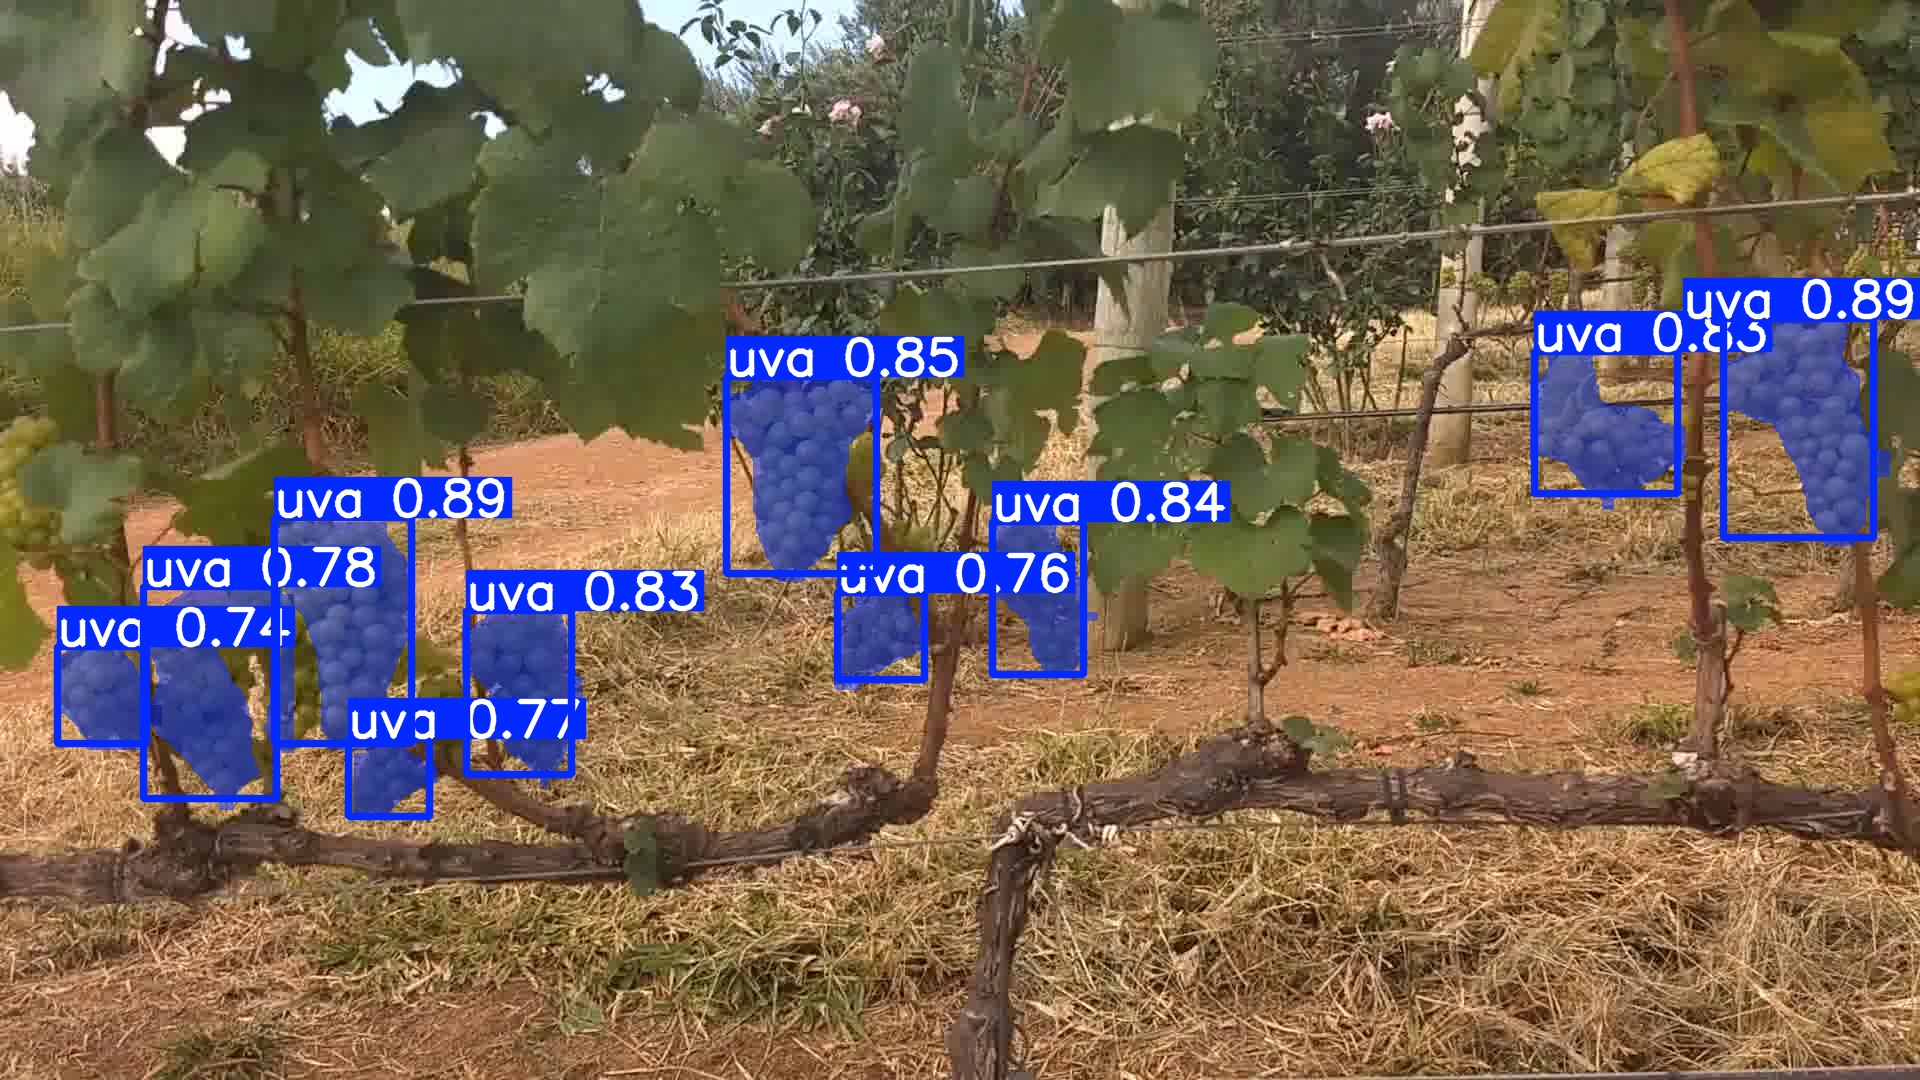

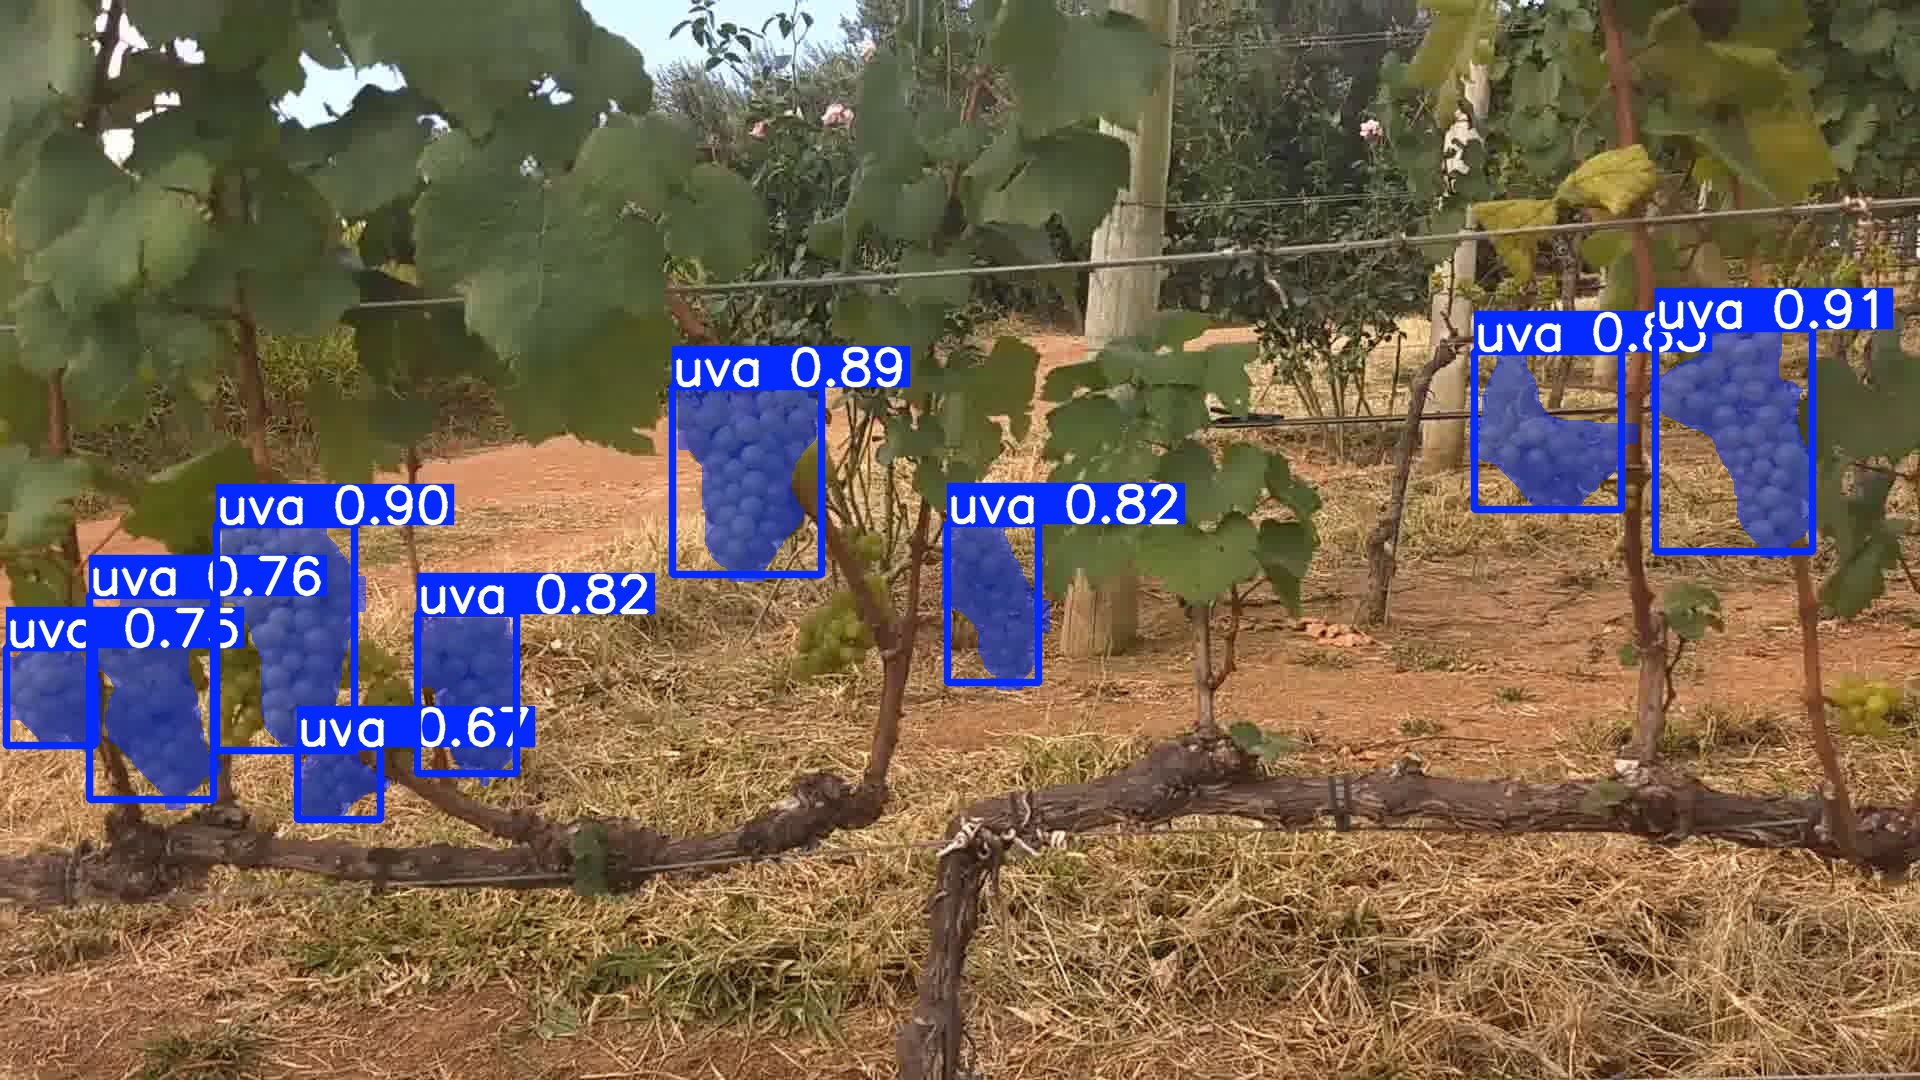

In [ ]:
from IPython.display import Image, display

# Mostra as 3 primeiras imagens resultantes do teste
fotos_resultado = [f for f in os.listdir(os.path.join(SAIDA_TESTE, 'experimento_1')) if f.endswith('.jpg')]
for foto in fotos_resultado[:10]:
    display(Image(filename=os.path.join(SAIDA_TESTE, 'experimento_1', foto)))